In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import quad
# Can get this plotting library from: https://github.com/aabiddanda/arjun_plot
from arjun_plot.utils import *
import polars as pl
from tqdm import tqdm
import sys
sys.path.append('../code/')
from macgregor import * 

plt.rc('font', family='Arial')

%matplotlib inline

In [2]:
# Some small verification steps to check the density of VAF integrates to 1
for age in np.arange(20,100, 5):
    integrand = quad(lambda x: freq_age_density(s=0.00)(x, age), 0, 0.5)[0]
    assert np.isclose(integrand, 1.0)

/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_82444/4183896246.py:3: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda x: freq_age_density(s=0.00)(x, age), 0, 0.5)[0]


In [3]:
tertp_df = pl.read_excel('../data/Table TERTp Age-VAF for Arjun_update 02-06-26 deidentified.xlsx', engine="calamine", read_options={"header_row": 2})
tertp_df.head()

Unique Pt ID,Age at sequencing,TERTp Mutation?,TERTp VAF,Ref_Forward,Ref_Reverse,Alt_F,Alt_R,Total Read Count,De-duplicated total read depth,Ref_F,Ref_R,Alt_F_1,Alt_R_1,Total,Pipeline
str,i64,str,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""523""",30,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""531""",30,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""392""",34,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""526""",34,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""539""",36,"""Yes""",30.3,515,637,233,267,1652,null,null,null,null,null,null,"""Clinical NGS on Research basis…"


In [4]:
# Process data from sheet into numpy arrays for likelihood inference
carrier_df = tertp_df.filter((pl.col('TERTp VAF') > 0) & (pl.col('TERTp VAF') < 50))
noncarrier_df = tertp_df.filter((pl.col('TERTp VAF') == 0))

# Get the carrier information
rs_carriers = np.nan_to_num(carrier_df['Alt_F'].to_numpy()) + np.nan_to_num(carrier_df['Alt_F_1'].to_numpy())
rs_carriers += np.nan_to_num(carrier_df['Alt_R'].to_numpy()) + np.nan_to_num(carrier_df['Alt_R_1'].to_numpy())
ds_carriers = np.nan_to_num(carrier_df['Total Read Count'].to_numpy()) + np.nan_to_num(carrier_df['Total'].to_numpy())
ts_carriers = carrier_df['Age at sequencing'].to_numpy()
assert rs_carriers.size == ts_carriers.size

# Get the non-carrier information
rs_noncarrier = np.zeros(noncarrier_df.shape[0])
ds_noncarrier = np.zeros(noncarrier_df.shape[0])
ts_noncarrier = noncarrier_df['Age at sequencing'].to_numpy()

# concatentate the carrier status
rs_total = np.hstack([rs_carriers, rs_noncarrier])
ds_total = np.hstack([ds_carriers, ds_noncarrier])
ts_total = np.hstack([ts_carriers, ts_noncarrier])

carrier_df.head()

Unique Pt ID,Age at sequencing,TERTp Mutation?,TERTp VAF,Ref_Forward,Ref_Reverse,Alt_F,Alt_R,Total Read Count,De-duplicated total read depth,Ref_F,Ref_R,Alt_F_1,Alt_R_1,Total,Pipeline
str,i64,str,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""539""",36,"""Yes""",30.3,515,637,233,267,1652,null,null,null,null,null,null,"""Clinical NGS on Research basis…"
"""539""",36,"""Yes""",6.6,672,499,56,27,1254,null,null,null,null,null,null,"""Clinical NGS on Research basis…"
"""522""",40,"""Yes""",9.0,1007,1206,95,124,2432,null,null,null,null,null,null,"""Clinical NGS"""
"""391""",45,"""Yes""",6.32,360,277,34,9,680,null,null,null,null,null,null,"""Clinical NGS"""
"""529""",47,"""Yes""",2.36,506,322,15,5,848,null,null,null,null,null,null,"""Clinical NGS"""


In [5]:
f = lambda x: -macgregor_total_loglik(rs_total, ds_total, ts_total, mu=x[0], s=x[1])
%time opt_res = minimize(f, x0=[1e-9, 1e-2], method='Powell', bounds=[(1e-20, 1e-6), (1e-10, 0.5)], options={'disp': True})

/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:42: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: binom.pmf(r2, n=d2, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:51: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: freq_age_density(s=s, mu=mu, **kwargs)(f, t), 0.0, f0)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:44: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: binom.pmf(r, n=d, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:67: RuntimeWarning: invalid value encountered in log
  loglik += np.log(macgregor_single_likelihood(r, d, t=t, s=s, mu=mu)

Optimization terminated successfully.
         Current function value: 155.654235
         Iterations: 2
         Function evaluations: 28
CPU times: user 4.13 s, sys: 163 ms, total: 4.29 s
Wall time: 4.13 s


In [6]:
opt_res

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 155.65423474564986
       x: [ 3.820e-07  2.421e-01]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00]]
    nfev: 28

In [18]:
# Estimate the confidence interval of mutation and selection parameters 
(s_lower, s_upper) = confint_s(rs_total, ds_total, ts_total, s_hat=opt_res.x[1], mu=opt_res.x[0])
(mu_lower, mu_upper) = confint_mu(rs_total, ds_total, ts_total, mu_hat=opt_res.x[0], s=opt_res.x[1])
print(s_lower, s_upper)
print(mu_lower, mu_upper)

/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:42: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: binom.pmf(r2, n=d2, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:42: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integrand = quad(lambda f: binom.pmf(r2, n=d2, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:51: Inte

0.21680026211260514 0.27348017013997855
2.578214113748251e-07 5.566293757479237e-07


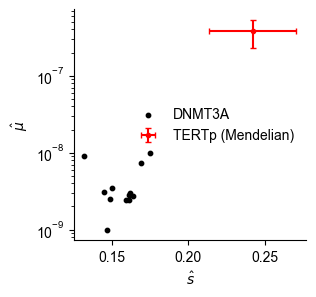

In [20]:
# Provides estimates of specific variants in the population-specific cohort ... 
macgregor_df = pl.read_csv('../data/Table_S3_constant_growth_CH_hotspots.csv')
fig ,ax = plt.subplots(1,1,figsize=(3,3))
test_df = macgregor_df.filter(pl.col('Variant').str.contains('DNMT3A'))
ax.scatter( test_df['s_per_year'].to_numpy(), test_df['mu_per_cell_per_year'].to_numpy(), label=r'DNMT3A', color='black', s=10)
ax.errorbar(opt_res.x[1], opt_res.x[0], marker='.', 
            xerr=(s_upper - s_lower)/2, yerr=(mu_upper - mu_lower)/2, capsize=2, linestyle='none', label=r'TERTp (Mendelian)', color='red')
ax.set_yscale('log')
ax.set_xlabel(r'$\hat{s}$')
ax.set_ylabel(r'$\hat{\mu}$')
ax.legend(frameon=False)
debox(ax)
plt.savefig('../plots/TERTp_mu_s.pdf', dpi=300, bbox_inches='tight')
plt.savefig('../plots/TERTp_mu_s.png', dpi=300, bbox_inches='tight')